In [16]:
import numpy
from astropy import units as u 
import agama
from scipy.optimize import brentq
import matplotlib.pyplot as plt 

In [17]:
def phi_eff_meridional(pot,R,z,Lz):
    pts = numpy.column_stack((R.ravel(), numpy.zeros(R.size), z.ravel()))  # x=R, y=0
    return (pot.potential(pts) + 0.5*Lz**2/R.ravel()**2).reshape(R.shape)

# Find the energy of a circular orbit given the radius
def circular_energy(R,pot):
    phi=pot.eval(numpy.array([R,0,0]),pot=True)
    dphi_dR = pot.eval(numpy.array([R,0,0]), acc=True)[0]
    return phi + 0.5 * R * dphi_dR

# now invert it 
def find_circular_radius_from_energy(E, potential, Rmin, Rmax):
    return brentq(lambda R: circular_energy(R, potential) - E,Rmin, Rmax)

def circular_radius_from_Lz(Lz, pot, Rmin, Rmax):
    def f(R):
        dphi_dR = pot.eval(numpy.array([R,0,0]), acc=True)[0]
        return numpy.abs(R**3 * dphi_dR) - Lz**2
    return brentq(f, Rmin, Rmax)

In [18]:
def unit_sphere(ntheta = 60, nphi = 120):
    theta=numpy.arccos(numpy.linspace(-1,1,ntheta))
    phi = numpy.linspace(0, 2*numpy.pi, nphi)
    TH, PH = numpy.meshgrid(theta, phi, indexing="ij")
    xhat=numpy.sin(TH)*numpy.cos(PH)
    yhat=numpy.sin(TH)*numpy.sin(PH)
    zhat=numpy.cos(TH)
    nhat=numpy.column_stack((xhat.flatten(),yhat.flatten(),zhat.flatten()))
    return nhat

In [19]:
unitL = u.kpc
unitV = u.km/u.s
unitM = u.Msun
agama.setUnits(mass=1, length=1, velocity=1)
G=agama.G
# set up the units

In [20]:
# set up the problem 
# initialize our potential 
potential   =   "McMillan17.ini"
path        =   agama.__path__[0] + "/data/" + "McMillan17.ini"
pot         =   agama.Potential(path)
massCluster =   1e5
scaleRadius =   5e-3
pot_cluster =   agama.Potential(type="plummer", mass=massCluster, scaleRadius=scaleRadius)

In [21]:
E0=pot.eval(numpy.array([0,0,0]),pot=True,)
E_test = E0/2
# what is circular? all of it is here, tight? 

get the zero velocity curve
$$\frac{\dot{R}^2}{2} + \frac{\dot{z}^2}{2} +\frac{L_z^2}
{2R^2} + \Phi(R,z) = E(R,z|L_z)$$

First, let's find the circular orbit for a given energy. There are two equations to use. 

1. The forces
$$ \frac{\partial \Phi (R,0)}{\partial R} = \frac{L_z^2}{R^3} $$

2. The energy 
$$E= \frac{L_z^2}{2R^2} + \Phi(R,0)$$
and subbing from the force condition 

$$E= \frac{R}{2}\frac{\partial \Phi (R,0)}{\partial R}  + \Phi(R,0)$$
Once Lz has been selected, we can solve this equatio numerically. 


In [70]:
Rmin=1e-4;Rmax=1e2
E       =   (4/5)*E0
Lz      =   5e1
Rc      =   find_circular_radius_from_energy(E, pot, Rmin, Rmax)
# Rc      =   circular_radius_from_Lz(Lz,pot,1e-3,2e1)

In [71]:
# get a bunch of directions and then modulate them with different radii to find the intersctions along a single direction 
# unit circle 
ntheta = int(11e1);nR=int(9)
xs = numpy.cos(numpy.linspace(0,2*numpy.pi,ntheta))
ys = numpy.sin(numpy.linspace(0,2*numpy.pi,ntheta))
nhat = numpy.column_stack((xs,ys))
# concentric circles
Ss = numpy.linspace(1e-3,Rc,nR)
concentric_circles = Ss[:,None,None] * nhat[None,:,:]
points_in_R_z_plane = numpy.reshape(concentric_circles.copy(),(-1,2))
points_in_R_z_plane +=  numpy.array([Rc,0]) # shift to where they are in the Rz plane
pts = numpy.column_stack((points_in_R_z_plane[:,0],0*points_in_R_z_plane[:,0],points_in_R_z_plane[:,1]))
# phi_circles = pot.eval(pts,pot=True)
# now reshape it so we get the potential along a direction 
# phi_circles=phi_circles.reshape(nR,ntheta)
# phi_circles.shape
phi_circles=phi_eff_meridional(pot,points_in_R_z_plane[:,0],points_in_R_z_plane[:,1],Lz)
phi_circles=phi_circles.reshape(nR,ntheta)

[None]

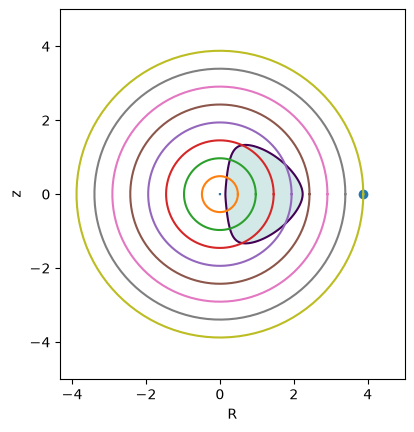

In [72]:
zmax = 5;Rmax = 5
Rg = numpy.linspace(1e-2, Rmax, 400)
zg = numpy.linspace(-zmax, zmax, 400)
RR, ZZ = numpy.meshgrid(Rg, zg, indexing="ij")
Peff = phi_eff_meridional(pot, RR, ZZ, Lz)

cs = plt.contour(RR, ZZ, Peff, levels=[E])   # the zero-velocity curve
plt.contourf(RR, ZZ, Peff <= E, levels=[0.5, 1], alpha=0.2)  # allowed region
plt.xlabel("R"); plt.ylabel("z")
plt.scatter(Rc,0)
for i in range(concentric_circles.shape[0]):
    plt.plot(concentric_circles[i,:,0] ,concentric_circles[i,:,1])

plt.gca().set(aspect="equal")

